# Single-Step ASPECT/FastScape VTK Zone and Species Test

This notebook reads one real ASPECT/FastScape VTK topography file, extracts river habitat zones from the VTK-provided `drainage_area` and `catchment` fields, initializes one fish species per extracted zone, and plots the resulting zone, species, and richness layers.

Because there is only one timestep, this notebook tests extraction and initialization only. It should not produce speciation events.

In [1]:
import importlib
import sys
from pathlib import Path

repo_root = Path.cwd().resolve()
if (repo_root / "src").exists():
    sys.path.insert(0, str(repo_root / "src"))

import numpy as np
import matplotlib.pyplot as plt

import magratheamorph.lineage as _morph_lineage
import magratheamorph.visualization as _morph_visualization
importlib.reload(_morph_lineage)
importlib.reload(_morph_visualization)

from magratheamorph.model import SpeciationModel
from magratheamorph.readers import read_vtk_dem
from magratheamorph.visualization import (
    plot_parent_daughter_tree,
    plot_richness_map,
    plot_species_map,
    plot_zone_map,
)
from magratheamorph.zones import ZoneExtractor


In [2]:
DATA_PATH = Path('/media/Samsung4TBSSD/research_data/tectonofish/output_fish_t1/Topography0000250.vtk')

# Tune these after inspecting the drainage-area plot.
MIN_DRAINAGE_AREA_PERCENTILE = 95
MIN_ZONE_CELLS = 25
GAP_TOLERANCE_CELLS = 1
USE_CATCHMENTS = True
MIN_ELEVATION = None
MAX_ELEVATION = None

print(DATA_PATH)
print('exists:', DATA_PATH.exists())


/media/Samsung4TBSSD/research_data/tectonofish/output_fish_t1/Topography0000250.vtk
exists: True


In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(DATA_PATH)

frame = read_vtk_dem(DATA_PATH, time=0.0)

print('Frame metadata')
for key, value in (frame.metadata or {}).items():
    print(f'  {key}: {value}')

print('\nGrid')
print('  shape:', frame.shape)
print('  x range:', float(np.nanmin(frame.x)), float(np.nanmax(frame.x)))
print('  y range:', float(np.nanmin(frame.y)), float(np.nanmax(frame.y)))
print('  cell area:', frame.cell_area)

print('\nElevation')
print('  min/max:', float(np.nanmin(frame.elevation)), float(np.nanmax(frame.elevation)))

if frame.drainage_area is None:
    raise ValueError('This notebook expects drainage_area in the VTK file.')
print('\nDrainage area')
print('  min/max:', float(np.nanmin(frame.drainage_area)), float(np.nanmax(frame.drainage_area)))
for percentile in [50, 75, 90, 95, 97, 99]:
    print(f'  p{percentile}:', float(np.nanpercentile(frame.drainage_area, percentile)))

if frame.catchment is not None:
    catchments = np.unique(frame.catchment[np.isfinite(frame.catchment)])
    print('\nCatchments')
    print('  count:', len(catchments))
    print('  first IDs:', catchments[:20])
else:
    print('\nCatchments: none')


Frame metadata
  path: /media/Samsung4TBSSD/research_data/tectonofish/output_fish_t1/Topography0000250.vtk
  reader: legacy_vtk_structured_grid
  elevation_field: topography
  drainage_area_field: drainage_area
  catchment_field: catchment

Grid
  shape: (115, 115)
  x range: 0.0 71250.0
  y range: 0.0 71250.0
  cell area: 390625.0

Elevation
  min/max: -369.6058654785156 91.80260467529297

Drainage area
  min/max: 390625.0 2265596160.0
  p50: 1232962.625
  p75: 3235852.5
  p90: 21731062.0
  p95: 48502355.99999999
  p97: 75573070.71999976
  p99: 362591822.08000153

Catchments
  count: 1
  first IDs: [0]


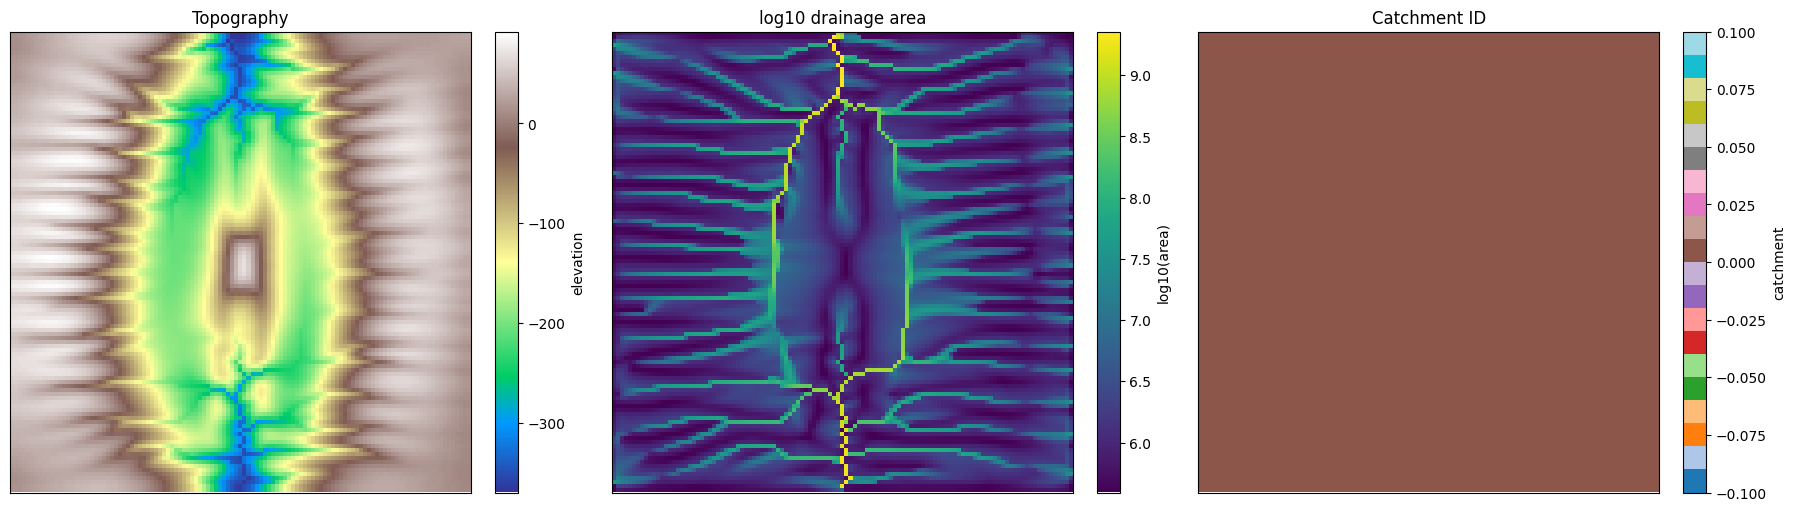

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

im0 = axes[0].imshow(frame.elevation, cmap='terrain', interpolation='nearest')
axes[0].set_title('Topography')
axes[0].set_xticks([])
axes[0].set_yticks([])
fig.colorbar(im0, ax=axes[0], label='elevation')

positive_drainage = np.where(frame.drainage_area > 0, frame.drainage_area, np.nan)
im1 = axes[1].imshow(np.log10(positive_drainage), cmap='viridis', interpolation='nearest')
axes[1].set_title('log10 drainage area')
axes[1].set_xticks([])
axes[1].set_yticks([])
fig.colorbar(im1, ax=axes[1], label='log10(area)')

if frame.catchment is not None:
    im2 = axes[2].imshow(frame.catchment, cmap='tab20', interpolation='nearest')
    axes[2].set_title('Catchment ID')
    fig.colorbar(im2, ax=axes[2], label='catchment')
else:
    axes[2].text(0.5, 0.5, 'No catchment field', ha='center', va='center', transform=axes[2].transAxes)
    axes[2].set_title('Catchment ID')
axes[2].set_xticks([])
axes[2].set_yticks([])

plt.show()


In [5]:
min_drainage_area = float(np.nanpercentile(frame.drainage_area, MIN_DRAINAGE_AREA_PERCENTILE))
print('Using min_drainage_area:', min_drainage_area)

extractor = ZoneExtractor(
    min_drainage_area=min_drainage_area,
    min_elevation=MIN_ELEVATION,
    max_elevation=MAX_ELEVATION,
    use_catchments=USE_CATCHMENTS,
    connectivity=8,
    min_zone_cells=MIN_ZONE_CELLS,
    gap_tolerance_cells=GAP_TOLERANCE_CELLS,
    habitat_mode=HABITAT_MODE,
)
zone_map = extractor.extract(frame)

print('Extracted zones:', len(zone_map.zones))
if zone_map.zones:
    areas = np.array([zone.area_cells for zone in zone_map.zones.values()])
    print('Zone area cells min/median/max:', int(areas.min()), float(np.median(areas)), int(areas.max()))
    print('First zone IDs:', sorted(zone_map.zones)[:20])
else:
    print('No zones extracted. Try lowering MIN_DRAINAGE_AREA_PERCENTILE or MIN_ZONE_CELLS.')


Using min_drainage_area: 48502355.99999999
Extracted zones: 2
Zone area cells min/median/max: 266 271.0 276
First zone IDs: [0, 1]


In [6]:
model = SpeciationModel(time_to_speciation=1)
model.initialize(zone_map)

print('Initial species:', len(model.species_table()))
print('Initial populations:', len(model.population_table()))
print('Events:')
for event in model.event_table():
    print(event)

richness_values = model.richness_map_at(zone_map)[zone_map.labels >= 0]
if richness_values.size:
    print('Richness values in occupied cells:', sorted(set(richness_values.tolist())))
else:
    print('No occupied cells in richness map')


Initial species: 2
Initial populations: 2
Events:
{'time': 0.0, 'event_type': 'species_origin', 'species_id': 0, 'parent_id': None}
{'time': 0.0, 'event_type': 'species_origin', 'species_id': 1, 'parent_id': None}
Richness values in occupied cells: [1]


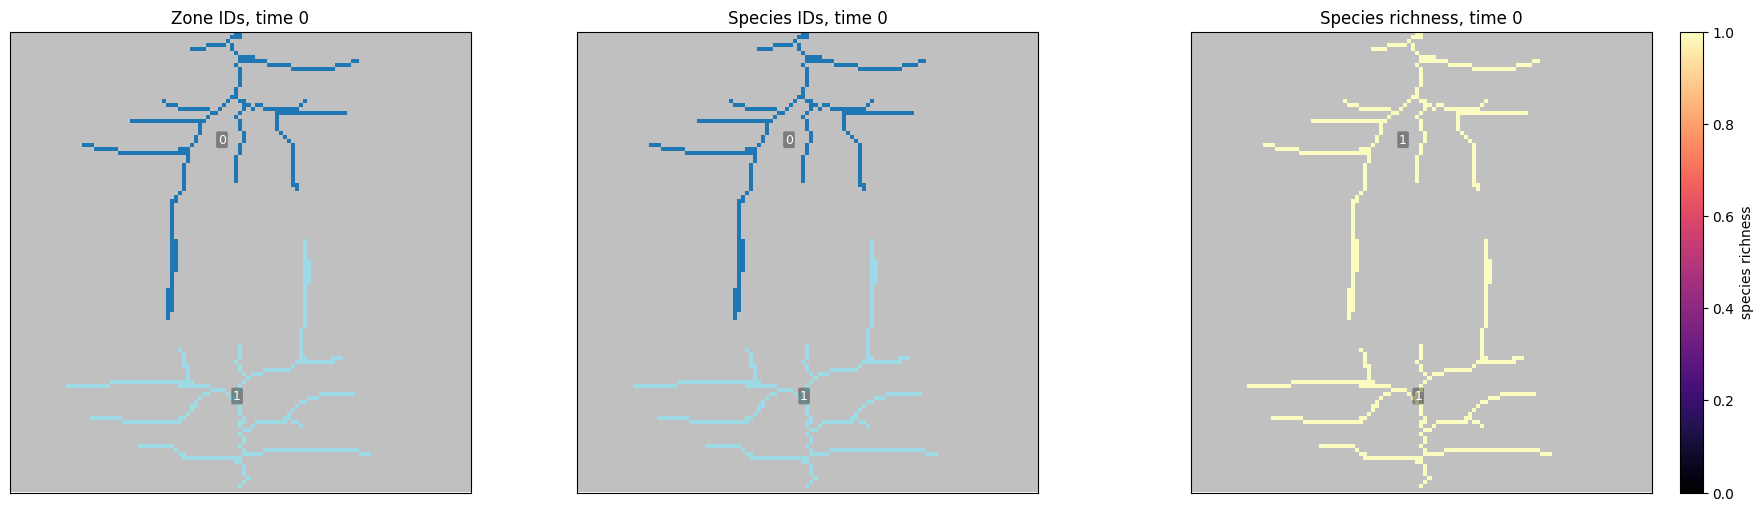

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
plot_zone_map(axes[0], zone_map, show_labels=True)
plot_species_map(axes[1], model, zone_map, max_labels_per_zone=8, show_labels=True)
im = plot_richness_map(axes[2], model, zone_map, show_labels=True)
fig.colorbar(im, ax=axes[2], label='species richness')
plt.show()


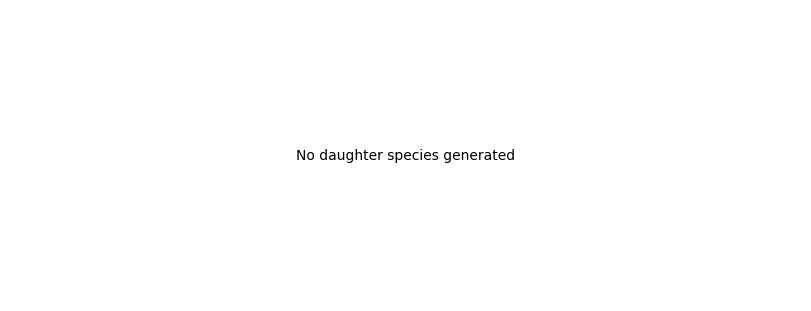

In [8]:
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
plot_parent_daughter_tree(
    ax,
    model.species_table(),
    end_time=zone_map.time,
    label_mode="all",
    max_labeled_species=10000,
    style="rectangular",
    time_unit="year",
    label_position="end",
    label_fontsize=6.5,
    time_block_cmap="Greens",
    time_block_count=5,
    show_time_blocks=True,
)
plt.show()


In [9]:
# Tables for checking extraction and initialization.
print('Zone summary')
for zone_id, zone in list(sorted(zone_map.zones.items()))[:30]:
    print({'zone_id': zone_id, 'area_cells': zone.area_cells, 'catchment_id': zone.catchment_id})
if len(zone_map.zones) > 30:
    print('...')

print('\nSpecies table')
for row in model.species_table()[:30]:
    print(row)
if len(model.species_table()) > 30:
    print('...')


Zone summary
{'zone_id': 0, 'area_cells': 266, 'catchment_id': 0}
{'zone_id': 1, 'area_cells': 276, 'catchment_id': 0}

Species table
{'species_id': 0, 'parent_id': None, 'origin_time': 0.0, 'extinction_time': None}
{'species_id': 1, 'parent_id': None, 'origin_time': 0.0, 'extinction_time': None}
